# Ejercicio — A* en servicios de nube

Una aplicación debe enviar una solicitud desde `Cliente` hasta `Servidor-Objetivo`.

Cada conexión tiene un costo que representa latencia y cada nodo tiene una heurística `h(n)`.

Recuerda:

**f(n) = g(n) + h(n)**

- `g(n)`: costo real acumulado.
- `h(n)`: estimación restante.
- `f(n)`: costo total estimado.

Durante la práctica no se modifica el algoritmo A*.


## 1. Librerías


In [5]:
import heapq
import networkx as nx
import matplotlib.pyplot as plt


## 2. Grafo


In [6]:
grafo = {
    'Cliente': [('Gateway-A', 2), ('Gateway-B', 1)],
    'Gateway-A': [('Cliente', 2), ('API-A', 2), ('API-B', 5)],
    'Gateway-B': [('Cliente', 1), ('API-B', 7), ('Cache', 2)],
    'API-A': [('Gateway-A', 2), ('Servidor-Objetivo', 3)],
    'API-B': [('Gateway-A', 5), ('Gateway-B', 7), ('Servidor-Objetivo', 2)],
    'Cache': [('Gateway-B', 2), ('Servidor-Objetivo', 8)],
    'Servidor-Objetivo': [('API-A', 3), ('API-B', 2), ('Cache', 8)]
}

inicio = 'Cliente'
meta = 'Servidor-Objetivo'


## 3. Heurística original


In [7]:
heuristica = {
    'Cliente': 7,
    'Gateway-A': 5,
    'Gateway-B': 3,
    'API-A': 3,
    'API-B': 1,
    'Cache': 5,
    'Servidor-Objetivo': 0
}


## 4. Visualización


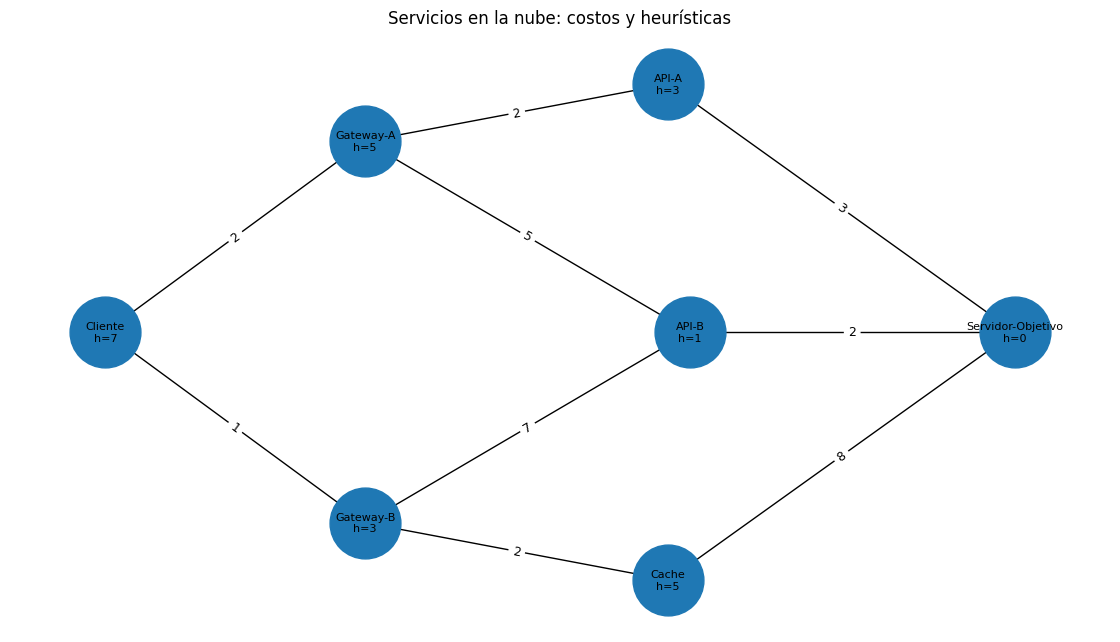

In [8]:
G = nx.Graph()

for nodo, vecinos in grafo.items():
    G.add_node(nodo)
    for vecino, costo in vecinos:
        G.add_edge(nodo, vecino, weight=costo)

pos = {
    'Cliente': (0, 1.5),
    'Gateway-A': (1.2, 2.5),
    'Gateway-B': (1.2, 0.5),
    'API-A': (2.6, 2.8),
    'API-B': (2.7, 1.5),
    'Cache': (2.6, 0.2),
    'Servidor-Objetivo': (4.2, 1.5)
}

plt.figure(figsize=(11, 6))

etiquetas = {
    nodo: f"{nodo}\nh={heuristica[nodo]}"
    for nodo in grafo
}

nx.draw(G, pos, with_labels=False, node_size=2600)
nx.draw_networkx_labels(G, pos, labels=etiquetas, font_size=8)

costos = nx.get_edge_attributes(G, 'weight')
nx.draw_networkx_edge_labels(G, pos, edge_labels=costos, font_size=9)

plt.title("Servicios en la nube: costos y heurísticas")
plt.show()


## 5. Algoritmo A*

No modifiques este algoritmo.


In [9]:
def a_estrella(grafo, heuristica, inicio, meta, mostrar=True):

    cola = [(heuristica[inicio], 0, 0, inicio, [inicio])]
    contador = 1
    mejor_costo = {inicio: 0}
    orden = []

    while cola:

        if mostrar:
            print("\nPendientes:")
            for f_p, g_p, _, nodo_p, _ in sorted(cola):
                print(nodo_p, "| g =", g_p,
                      "| h =", heuristica[nodo_p],
                      "| f =", f_p)

        f, g, _, nodo, camino = heapq.heappop(cola)

        if g != mejor_costo.get(nodo):
            continue

        orden.append(nodo)

        if mostrar:
            print("\nExplorando:", nodo,
                  "| g =", g,
                  "| h =", heuristica[nodo],
                  "| f =", f,
                  "| ruta:", " -> ".join(camino))

        if nodo == meta:
            return orden, camino, g

        for vecino, costo in grafo.get(nodo, []):

            nuevo_g = g + costo

            if vecino not in mejor_costo or nuevo_g < mejor_costo[vecino]:

                mejor_costo[vecino] = nuevo_g
                nuevo_f = nuevo_g + heuristica[vecino]

                heapq.heappush(
                    cola,
                    (nuevo_f, nuevo_g, contador,
                     vecino, camino + [vecino])
                )

                contador += 1

    return orden, None, None


# Caso 1. Heurística y costos originales

Ejecuta A* sin modificar nada.


In [10]:
orden, camino, costo = a_estrella(
    grafo, heuristica, inicio, meta
)

print("\nOrden:", orden)
print("Camino:", camino)
print("Costo total:", costo)



Pendientes:
Cliente | g = 0 | h = 7 | f = 7

Explorando: Cliente | g = 0 | h = 7 | f = 7 | ruta: Cliente

Pendientes:
Gateway-B | g = 1 | h = 3 | f = 4
Gateway-A | g = 2 | h = 5 | f = 7

Explorando: Gateway-B | g = 1 | h = 3 | f = 4 | ruta: Cliente -> Gateway-B

Pendientes:
Gateway-A | g = 2 | h = 5 | f = 7
Cache | g = 3 | h = 5 | f = 8
API-B | g = 8 | h = 1 | f = 9

Explorando: Gateway-A | g = 2 | h = 5 | f = 7 | ruta: Cliente -> Gateway-A

Pendientes:
API-A | g = 4 | h = 3 | f = 7
Cache | g = 3 | h = 5 | f = 8
API-B | g = 7 | h = 1 | f = 8
API-B | g = 8 | h = 1 | f = 9

Explorando: API-A | g = 4 | h = 3 | f = 7 | ruta: Cliente -> Gateway-A -> API-A

Pendientes:
Servidor-Objetivo | g = 7 | h = 0 | f = 7
Cache | g = 3 | h = 5 | f = 8
API-B | g = 7 | h = 1 | f = 8
API-B | g = 8 | h = 1 | f = 9

Explorando: Servidor-Objetivo | g = 7 | h = 0 | f = 7 | ruta: Cliente -> Gateway-A -> API-A -> Servidor-Objetivo

Orden: ['Cliente', 'Gateway-B', 'Gateway-A', 'API-A', 'Servidor-Objetivo']
Camin

### Preguntas — Caso 1

1. ¿Qué nodo exploró A* después de Cliente?
Exploró Gateway-B.

2. ¿Cuál fue el valor de `f` de Gateway-A?
El valor de f fue 7 (g=2 + h=5).

3. ¿Cuál fue el valor de `f` de Gateway-B?
El valor de f fue 4 (g=1 + h=3).

4. ¿Cuál fue el camino final?
Cliente -> Gateway-A -> API-A -> Servidor-Objetivo

5. ¿Cuál fue el costo total?
El costo total fue 7.

6. ¿El primer nodo seleccionado después de Cliente quedó finalmente en el camino solución?
No, Gateway-B fue el primero seleccionado pero no formó parte del camino final (que usó Gateway-A).

# Caso 2. Cambiar heurísticas

Modifica únicamente:

- `Gateway-A: 5 → 2`
- `Gateway-B: 3 → 6`

No cambies los costos.


In [11]:
heuristica = {
    'Cliente': 7,
    'Gateway-A': 2,
    'Gateway-B': 6,
    'API-A': 3,
    'API-B': 1,
    'Cache': 5,
    'Servidor-Objetivo': 0
}

orden, camino, costo = a_estrella(
    grafo, heuristica, inicio, meta
)

print("\nOrden:", orden)
print("Camino:", camino)
print("Costo total:", costo)



Pendientes:
Cliente | g = 0 | h = 7 | f = 7

Explorando: Cliente | g = 0 | h = 7 | f = 7 | ruta: Cliente

Pendientes:
Gateway-A | g = 2 | h = 2 | f = 4
Gateway-B | g = 1 | h = 6 | f = 7

Explorando: Gateway-A | g = 2 | h = 2 | f = 4 | ruta: Cliente -> Gateway-A

Pendientes:
Gateway-B | g = 1 | h = 6 | f = 7
API-A | g = 4 | h = 3 | f = 7
API-B | g = 7 | h = 1 | f = 8

Explorando: Gateway-B | g = 1 | h = 6 | f = 7 | ruta: Cliente -> Gateway-B

Pendientes:
API-A | g = 4 | h = 3 | f = 7
Cache | g = 3 | h = 5 | f = 8
API-B | g = 7 | h = 1 | f = 8

Explorando: API-A | g = 4 | h = 3 | f = 7 | ruta: Cliente -> Gateway-A -> API-A

Pendientes:
Servidor-Objetivo | g = 7 | h = 0 | f = 7
Cache | g = 3 | h = 5 | f = 8
API-B | g = 7 | h = 1 | f = 8

Explorando: Servidor-Objetivo | g = 7 | h = 0 | f = 7 | ruta: Cliente -> Gateway-A -> API-A -> Servidor-Objetivo

Orden: ['Cliente', 'Gateway-A', 'Gateway-B', 'API-A', 'Servidor-Objetivo']
Camino: ['Cliente', 'Gateway-A', 'API-A', 'Servidor-Objetivo']
Co

### Preguntas — Caso 2

1. ¿Qué gateway se exploró primero?
Se exploró primero Gateway-A.

2. ¿Cambió el orden de exploración?
Sí, ahora se exploró Gateway-A antes que Gateway-B debido a que su heurística bajó de 5 a 2.

3. ¿Cambió el camino final?
No, el camino final siguió siendo Cliente -> Gateway-A -> API-A -> Servidor-Objetivo.

4. ¿Cambió el costo real?
No, el costo real siguió siendo 7.

5. ¿Por qué cambiar `h(n)` puede cambiar el orden aunque el grafo sea el mismo?
Porque h(n) modifica el valor de f(n), que es el valor que utiliza la cola de prioridad para decidir qué nodo explorar primero.

# Caso 3. Favorecer una rama cambiando costos

Restaura las heurísticas originales.

Ahora favorece:

`Cliente → Gateway-B → Cache → Servidor-Objetivo`

Cambia:

- `Gateway-B ↔ Cache: 2 → 1`
- `Cache ↔ Servidor-Objetivo: 8 → 2`


In [12]:
heuristica = {
    'Cliente': 7,
    'Gateway-A': 5,
    'Gateway-B': 3,
    'API-A': 3,
    'API-B': 1,
    'Cache': 5,
    'Servidor-Objetivo': 0
}

grafo = {
    'Cliente': [('Gateway-A', 2), ('Gateway-B', 1)],
    'Gateway-A': [('Cliente', 2), ('API-A', 2), ('API-B', 5)],
    'Gateway-B': [('Cliente', 1), ('API-B', 7), ('Cache', 1)],
    'API-A': [('Gateway-A', 2), ('Servidor-Objetivo', 3)],
    'API-B': [('Gateway-A', 5), ('Gateway-B', 7), ('Servidor-Objetivo', 2)],
    'Cache': [('Gateway-B', 1), ('Servidor-Objetivo', 2)],
    'Servidor-Objetivo': [('API-A', 3), ('API-B', 2), ('Cache', 2)]
}

orden, camino, costo = a_estrella(
    grafo, heuristica, inicio, meta
)

print("\nOrden:", orden)
print("Camino:", camino)
print("Costo total:", costo)



Pendientes:
Cliente | g = 0 | h = 7 | f = 7

Explorando: Cliente | g = 0 | h = 7 | f = 7 | ruta: Cliente

Pendientes:
Gateway-B | g = 1 | h = 3 | f = 4
Gateway-A | g = 2 | h = 5 | f = 7

Explorando: Gateway-B | g = 1 | h = 3 | f = 4 | ruta: Cliente -> Gateway-B

Pendientes:
Gateway-A | g = 2 | h = 5 | f = 7
Cache | g = 2 | h = 5 | f = 7
API-B | g = 8 | h = 1 | f = 9

Explorando: Gateway-A | g = 2 | h = 5 | f = 7 | ruta: Cliente -> Gateway-A

Pendientes:
Cache | g = 2 | h = 5 | f = 7
API-A | g = 4 | h = 3 | f = 7
API-B | g = 7 | h = 1 | f = 8
API-B | g = 8 | h = 1 | f = 9

Explorando: Cache | g = 2 | h = 5 | f = 7 | ruta: Cliente -> Gateway-B -> Cache

Pendientes:
Servidor-Objetivo | g = 4 | h = 0 | f = 4
API-A | g = 4 | h = 3 | f = 7
API-B | g = 7 | h = 1 | f = 8
API-B | g = 8 | h = 1 | f = 9

Explorando: Servidor-Objetivo | g = 4 | h = 0 | f = 4 | ruta: Cliente -> Gateway-B -> Cache -> Servidor-Objetivo

Orden: ['Cliente', 'Gateway-B', 'Gateway-A', 'Cache', 'Servidor-Objetivo']
Camin

### Preguntas — Caso 3

1. ¿Cambió el camino?
Sí, ahora el camino es Cliente -> Gateway-B -> Cache -> Servidor-Objetivo.

2. ¿Cuál es ahora el costo total?
El costo total es 4.

3. ¿Qué cambió en este caso: `g(n)`, `h(n)` o ambos?
Cambió g(n), que es el costo real de las conexiones en el grafo. Las heurísticas h(n) se mantuvieron iguales.

4. ¿Por qué disminuir un costo afecta a `f(n)`?
Porque f(n) se calcula como g(n) + h(n). Al disminuir el costo del enlace, g(n) se reduce y por lo tanto f(n) también disminuye.

5. ¿Qué diferencia observas respecto del Caso 2?
En el Caso 2 se modificó la estimación (heurística) para guiar la búsqueda, mientras que en el Caso 3 se modificaron los costos reales del entorno para cambiar la ruta óptima verdadera.

# Caso 4. Favorecer otra rama

Intenta conseguir:

`Cliente → Gateway-A → API-B → Servidor-Objetivo`

Puedes modificar heurísticas y costos, pero:

- no elimines nodos;
- no agregues conexiones;
- `h(Servidor-Objetivo)=0`.


In [13]:
heuristica = {
    'Cliente': 7,
    'Gateway-A': 1,
    'Gateway-B': 10,
    'API-A': 10,
    'API-B': 1,
    'Cache': 10,
    'Servidor-Objetivo': 0
}

grafo = {
    'Cliente': [('Gateway-A', 2), ('Gateway-B', 1)],
    'Gateway-A': [('Cliente', 2), ('API-A', 2), ('API-B', 2)],
    'Gateway-B': [('Cliente', 1), ('API-B', 7), ('Cache', 2)],
    'API-A': [('Gateway-A', 2), ('Servidor-Objetivo', 3)],
    'API-B': [('Gateway-A', 2), ('Gateway-B', 7), ('Servidor-Objetivo', 2)],
    'Cache': [('Gateway-B', 2), ('Servidor-Objetivo', 8)],
    'Servidor-Objetivo': [('API-A', 3), ('API-B', 2), ('Cache', 8)]
}

orden, camino, costo = a_estrella(
    grafo, heuristica, inicio, meta
)

print("\nOrden:", orden)
print("Camino:", camino)
print("Costo total:", costo)


Pendientes:
Cliente | g = 0 | h = 7 | f = 7

Explorando: Cliente | g = 0 | h = 7 | f = 7 | ruta: Cliente

Pendientes:
Gateway-A | g = 2 | h = 1 | f = 3
Gateway-B | g = 1 | h = 10 | f = 11

Explorando: Gateway-A | g = 2 | h = 1 | f = 3 | ruta: Cliente -> Gateway-A

Pendientes:
API-B | g = 4 | h = 1 | f = 5
Gateway-B | g = 1 | h = 10 | f = 11
API-A | g = 4 | h = 10 | f = 14

Explorando: API-B | g = 4 | h = 1 | f = 5 | ruta: Cliente -> Gateway-A -> API-B

Pendientes:
Servidor-Objetivo | g = 6 | h = 0 | f = 6
Gateway-B | g = 1 | h = 10 | f = 11
API-A | g = 4 | h = 10 | f = 14

Explorando: Servidor-Objetivo | g = 6 | h = 0 | f = 6 | ruta: Cliente -> Gateway-A -> API-B -> Servidor-Objetivo

Orden: ['Cliente', 'Gateway-A', 'API-B', 'Servidor-Objetivo']
Camino: ['Cliente', 'Gateway-A', 'API-B', 'Servidor-Objetivo']
Costo total: 6


### Preguntas — Caso 4

1. ¿Qué heurísticas modificaste?
Subí las heurísticas de Gateway-B, API-A y Cache a 10 para desincentivarlas, y bajé las de Gateway-A y API-B a 1.

2. ¿Qué costos modificaste?
Modifiqué el costo de la conexión entre Gateway-A y API-B reduciéndolo de 5 a 2.

3. ¿Lograste obtener la ruta solicitada?
Sí, se obtuvo la ruta Cliente -> Gateway-A -> API-B -> Servidor-Objetivo.

4. ¿Qué valores de `g`, `h` y `f` fueron determinantes?
El bajo valor de f en el camino por API-B (g=4, h=1, f=5) y el alto valor de f por las otras rutas alternativas.

5. ¿Bastó con cambiar solamente la heurística?
No, porque el costo real acumulado (g) original para esa ruta era alto, por lo que fue necesario ajustar el costo para hacerla óptima.

6. ¿Por qué A* no depende únicamente de `h(n)`?
Porque si dependiera solo de h(n) sería un algoritmo de búsqueda codiciosa (Greedy), el cual ignora el costo real ya recorrido y puede tomar rutas ineficientes.

# Caso 5. Diseña tu propio escenario

Diseña tus propios valores de heurística y costos.

### Reglas

- no agregues nodos;
- no elimines nodos;
- no agregues conexiones;
- `h(Servidor-Objetivo)=0`;
- escribe primero qué ruta esperas obtener.


In [14]:
heuristica = {
    'Cliente': 5,
    'Gateway-A': 10,
    'Gateway-B': 1,
    'API-A': 10,
    'API-B': 1,
    'Cache': 10,
    'Servidor-Objetivo': 0
}

grafo = {
    'Cliente': [('Gateway-A', 2), ('Gateway-B', 1)],
    'Gateway-A': [('Cliente', 2), ('API-A', 2), ('API-B', 5)],
    'Gateway-B': [('Cliente', 1), ('API-B', 2), ('Cache', 2)],
    'API-A': [('Gateway-A', 2), ('Servidor-Objetivo', 3)],
    'API-B': [('Gateway-A', 5), ('Gateway-B', 2), ('Servidor-Objetivo', 2)],
    'Cache': [('Gateway-B', 2), ('Servidor-Objetivo', 8)],
    'Servidor-Objetivo': [('API-A', 3), ('API-B', 2), ('Cache', 8)]
}

orden, camino, costo = a_estrella(
    grafo, heuristica, inicio, meta
)

print("\nOrden:", orden)
print("Camino:", camino)
print("Costo total:", costo)


Pendientes:
Cliente | g = 0 | h = 5 | f = 5

Explorando: Cliente | g = 0 | h = 5 | f = 5 | ruta: Cliente

Pendientes:
Gateway-B | g = 1 | h = 1 | f = 2
Gateway-A | g = 2 | h = 10 | f = 12

Explorando: Gateway-B | g = 1 | h = 1 | f = 2 | ruta: Cliente -> Gateway-B

Pendientes:
API-B | g = 3 | h = 1 | f = 4
Gateway-A | g = 2 | h = 10 | f = 12
Cache | g = 3 | h = 10 | f = 13

Explorando: API-B | g = 3 | h = 1 | f = 4 | ruta: Cliente -> Gateway-B -> API-B

Pendientes:
Servidor-Objetivo | g = 5 | h = 0 | f = 5
Gateway-A | g = 2 | h = 10 | f = 12
Cache | g = 3 | h = 10 | f = 13

Explorando: Servidor-Objetivo | g = 5 | h = 0 | f = 5 | ruta: Cliente -> Gateway-B -> API-B -> Servidor-Objetivo

Orden: ['Cliente', 'Gateway-B', 'API-B', 'Servidor-Objetivo']
Camino: ['Cliente', 'Gateway-B', 'API-B', 'Servidor-Objetivo']
Costo total: 5


### Preguntas — Caso 5

1. ¿Qué ruta esperabas obtener?
Esperaba obtener la ruta: Cliente -> Gateway-B -> API-B -> Servidor-Objetivo.

2. ¿Qué ruta obtuvo A*?
Obtuvo la ruta: Cliente -> Gateway-B -> API-B -> Servidor-Objetivo.

3. ¿Cuál fue el costo?
El costo total fue 5.

4. ¿Qué valores modificaste?
Reduje el costo de la conexión entre Gateway-B y API-B de 7 a 2, y ajusté las heurísticas para favorecer esa rama.

5. ¿Qué tuvo mayor influencia en tu caso: `g(n)` o `h(n)`?
Ambas influyeron, pero g(n) fue determinante para que la ruta realmente tuviera un costo bajo factible.

6. ¿Qué relación observaste entre `g(n)`, `h(n)` y `f(n)`?
Que f(n) es la suma de ambos. Una h(n) baja ayuda a priorizar el nodo, pero si g(n) es demasiado alta, la suma f(n) terminará siendo descartada por opciones más baratas.

7. ¿Por qué una heurística pequeña no garantiza por sí sola que un nodo sea la mejor opción?
Porque si el costo acumulado g(n) para llegar a ese nodo es extremadamente alto, el valor total f(n) seguirá siendo malo.

8. ¿Cuál es la diferencia principal entre Greedy y A*?
Greedy solo toma decisiones basándose en la estimación h(n) hacia el objetivo sin importar cuánto ha costado llegar allí, mientras que A* equilibra el costo real ya pagado g(n) con la estimación futura h(n).

## Conclusión

- g(n) representa el costo real acumulado desde el nodo inicial hasta el nodo actual.
- h(n) representa la estimación del costo restante desde el nodo actual hasta el nodo objetivo.
- f(n) representa el costo total estimado de la ruta que pasa por el nodo actual.
- A* decide explorando siempre el nodo con el menor valor de f(n) en la cola de pendientes.
- Los costos son importantes porque reflejan la realidad física o lógica de la red, garantizando que encontremos el camino más corto real.
- La diferencia fundamental es que Greedy es impaciente y solo mira el futuro estimado h(n), mientras que A* es óptimo porque suma el pasado real g(n) con el futuro estimado h(n).